# Años de vida que quedan a los 65

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "esperanza-vida-65"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Años de vida que quedan a los 65"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "años"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/
MAX_ERROR_APROX = 0.3  # años: error máximo admitido de la media de hombres y mujeres frente al total publicado

## 1. Contexto

**Qué mide.** La media de los años que vivirían a partir de esa edad las personas que cumplen 65 si a lo largo de su vida se mantuvieran las tasas de mortalidad por edad de ese año. Es la *esperanza de vida a los 65 años*, para hombres y mujeres juntos.

**Cómo se lee.** Es un promedio, no lo que vivirá cada persona: un valor de 20 significa que, con la mortalidad de ese año, las personas de 65 vivirían de media 20 años más; unas vivirán más y otras menos.

**Por qué está en este tema.** Lo que liga la edad de jubilación con el coste de las pensiones es cuántos años se cobra la pensión: si a la misma edad de jubilación se vive más, se cobra durante más tiempo. Es el dato que usan los mecanismos que ajustan la pensión inicial o la edad de jubilación a la longevidad (como el factor de sostenibilidad de la Ley 23/2013) y las propuestas de ligar la edad de jubilación a la esperanza de vida.

**Limitaciones.**
- Es una esperanza de vida *del periodo*: se calcula con la mortalidad de cada año, no con la que vivirá cada generación, que suele ser más baja. Por eso cae en años de mortalidad excepcional, como 2020 por la covid, aunque la tendencia de fondo no cambie.
- No dice cuántos de esos años se viven con buena salud ni cuántos se cobra una pensión: la edad efectiva de jubilación varía entre personas y países.
- **EE. UU. y Canadá: cálculo propio.** La OCDE publica la esperanza de vida a los 65 años de esos países solo por sexo, no la total. Aquí se usa la media simple de la de los hombres y la de las mujeres, y la sección 3 comprueba con los datos de Eurostat de España y la UE-27, que publican las tres, cuánto se aleja esa media del total. La OCDE no publica su media para esta edad.

## 2. Descarga

- **España y UE-27:** Eurostat, esperanza de vida por edad y sexo (`demo_mlexpec`), 65 años (`Y65`), total (`T`) y, para la comprobación, hombres (`M`) y mujeres (`F`), en años (`YR`).
- **EE. UU. y Canadá:** OCDE, estado de salud, esperanza de vida (`OECD.ELS.HD,DSD_HEALTH_STAT@DF_LE,1.1`), `LFEXP` a los 65 años (`Y65`), hombres y mujeres. También España, para compararla con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

eu = {}
for sexo in ("T", "M", "F"):
    eu[sexo], f = eurostat.get("demo_mlexpec", {"freq": "A", "age": "Y65", "sex": sexo, "unit": "YR"}, desde=DESDE)
    if sexo == "T":
        fuentes_eu = f

# OCDE: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.AGE.SEX.SOCIO_ECON_STATUS.DEATH_CAUSE.CALC_METHODOLOGY.
#       GESTATION_THRESHOLD.HEALTH_STATUS.DISEASE.CANCER_SITE
DATAFLOW_LE = "OECD.ELS.HD,DSD_HEALTH_STAT@DF_LE,1.1"
AREAS = {"USA": "eeuu", "CAN": "canada", "ESP": "espana_ocde"}
oc = {}
for sexo in ("M", "F"):
    oc[sexo], _ = oecd.get(DATAFLOW_LE, f"{{AREA}}.A.LFEXP.Y.Y65.{sexo}._Z._Z._Z._Z._Z._Z._Z", areas=AREAS, desde=DESDE)
# ¿Publica ya la OCDE el total a los 65 años o su media? (si lo hace, hay que usarlo en lugar del cálculo propio)
try:
    total_oc, _ = oecd.get(DATAFLOW_LE, "{AREA}.A.LFEXP.Y.Y65._T._Z._Z._Z._Z._Z._Z._Z",
                           areas={**AREAS, "OECD": "ocde"}, desde=DESDE)
except oecd.OecdError:
    total_oc = pd.DataFrame(columns=["serie", "periodo", "valor"])
print("Total a los 65 en la OCDE:", sorted(total_oc["serie"].unique()) or "no publicado")

Total a los 65 en la OCDE: no publicado


## 3. Transformación

- **España y UE-27:** el total de Eurostat, sin transformar.
- **EE. UU. y Canadá:** media simple de la esperanza de vida a los 65 años de hombres y mujeres de la OCDE, solo en los años con las dos. Antes se comprueba el error de esa aproximación con Eurostat, que publica las tres series para España y la UE-27.
- **OCDE:** `null`.

In [ ]:
assert total_oc.empty, "la OCDE publica ya el total a los 65 años: usarlo en lugar de la media de hombres y mujeres"
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]


def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


# Comprobación de la aproximación con Eurostat
errores = {}
for g in ("espana", "ue27"):
    t = pd.DataFrame({"total": serie(eu["T"], g), "media H/M": (serie(eu["M"], g) + serie(eu["F"], g)) / 2}).dropna()
    t["error"] = t["media H/M"] - t["total"]
    errores[g] = t["error"]
    print(g, f"error de la media simple: entre {t['error'].min():.2f} y {t['error'].max():.2f} años")
ERROR_MAX = max(e.abs().max() for e in errores.values())
ERROR_SIGNO = max(e.max() for e in errores.values())  # < 0: la media siempre queda por debajo del total
assert ERROR_MAX <= MAX_ERROR_APROX, f"la media de hombres y mujeres se aleja {ERROR_MAX:.2f} años del total"

# España: OCDE frente a Eurostat, por sexo
comp = pd.DataFrame({
    f"{s} OCDE − Eurostat": serie(oc[s], "espana_ocde") - serie(eu[s], "espana") for s in ("M", "F")
}).dropna()
DIF_ES = comp.abs().max().max()
print(f"España, OCDE − Eurostat por sexo: diferencia máxima {DIF_ES:.2f} años ({comp.index.min()}-{comp.index.max()})")

partes = []
for s in ("eeuu", "canada"):
    m = pd.DataFrame({"M": serie(oc["M"], s), "F": serie(oc["F"], s)}).dropna()
    partes.append(pd.DataFrame({"serie": s, "periodo": m.index, "valor": m.mean(axis=1).values}))
df = pd.concat([eu["T"], *partes], ignore_index=True)

HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "demo_mlexpec (age=Y65, sex=T, unit=YR)", f.url, f.fecha_consulta) for f in fuentes_eu
] + [
    FuenteMeta(s, oecd.ORGANISMO, "DSD_HEALTH_STAT@DF_LE (LFEXP, Y65): media simple de hombres y mujeres (cálculo propio)",
               oecd.URL_EXPLORER, HOY)
    for s in ("eeuu", "canada")
]
vacia = pd.DataFrame({"serie": ["ocde"], "periodo": [DESDE], "valor": [float("nan")]})
df = pd.concat([df, vacia], ignore_index=True)
fuentes.append(FuenteMeta("ocde", oecd.ORGANISMO, "DSD_HEALTH_STAT@DF_LE (LFEXP, Y65): sin media de la OCDE", oecd.URL_EXPLORER, HOY))
assert df["valor"].dropna().between(10, 30).all(), "valor fuera de rango: ¿unidades?"

huecos = {
    s: sorted(set(range(int(g["periodo"].min()), int(g["periodo"].max()) + 1)) - set(g["periodo"]))
    for s, g in df.dropna().groupby("serie")
}
print("Años sin dato dentro de cada serie:", {s: h for s, h in huecos.items() if h})
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(8)

espana error de la media simple: entre -0.20 y -0.05 años
ue27 error de la media simple: entre -0.20 y -0.10 años
España, OCDE − Eurostat por sexo: diferencia máxima 0.00 años (1976-2024)
Años sin dato dentro de cada serie: {'canada': [1977, 1978]}


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2017,20.70,19.30,21.1,NaN,19.7
2018,20.75,19.40,21.2,NaN,19.8
2019,20.90,19.50,21.5,NaN,20.0
2020,20.65,18.40,20.3,NaN,19.2
2021,20.80,18.35,21.1,NaN,19.1
2022,20.40,18.85,21.1,NaN,19.4
2023,20.90,19.45,21.7,NaN,20.0
2024,21.15,19.60,21.9,NaN,20.2


### Notas

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


HUECOS_CAN = huecos.get("canada", [])
NOTAS = [
    "España y UE-27: Eurostat, esperanza de vida a los 65 años, ambos sexos (demo_mlexpec, Y65, T). Media UE-27: "
    "agregado de composición actual (EU27_2020).",
    f"EE. UU. y Canadá: cálculo propio, media simple de la esperanza de vida a los 65 años de hombres y de mujeres "
    f"que publica la OCDE (DSD_HEALTH_STAT@DF_LE, LFEXP), que no publica el total a esa edad. Con los datos de "
    f"Eurostat de España y la UE-27, esa media "
    + (f"queda por debajo del total publicado, como mucho {fmt(ERROR_MAX, 2)} años." if ERROR_SIGNO < 0 else
       f"se aleja del total publicado como mucho {fmt(ERROR_MAX, 2)} años."),
    *([f"Canadá: sin dato en {unir(HUECOS_CAN)}."] if HUECOS_CAN else []),
    "OCDE: sin dato. La OCDE no publica su media de la esperanza de vida a los 65 años.",
    "España en las dos fuentes: la esperanza de vida a los 65 años de hombres y de mujeres de la OCDE "
    + ("coincide con la de Eurostat." if DIF_ES < 0.005 else f"difiere de la de Eurostat como mucho {fmt(DIF_ES, 2)} años."),
    "Es una esperanza de vida del periodo, calculada con la mortalidad de cada año: baja en 2020 por la mortalidad "
    "de la covid, y no es la que vivirá cada generación.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, esperanza de vida a los 65 años, ambos sexos (demo_mlexpec, Y65, T). Media UE-27: agregado de composición actual (EU27_2020).
- EE. UU. y Canadá: cálculo propio, media simple de la esperanza de vida a los 65 años de hombres y de mujeres que publica la OCDE (DSD_HEALTH_STAT@DF_LE, LFEXP), que no publica el total a esa edad. Con los datos de Eurostat de España y la UE-27, esa media queda por debajo del total publicado, como mucho 0,20 años.
- Canadá: sin dato en 1977 y 1978.
- OCDE: sin dato. La OCDE no publica su media de la esperanza de vida a los 65 años.
- España en las dos fuentes: la esperanza de vida a los 65 años de hombres y de mujeres de la OCDE coincide con la de Eurostat.
- Es una esperanza de vida del periodo, calculada con la mortalidad de cada año: baja en 2020 por la mortalidad de la covid, y no es la que vivirá cada generación.


## 4. Visualización

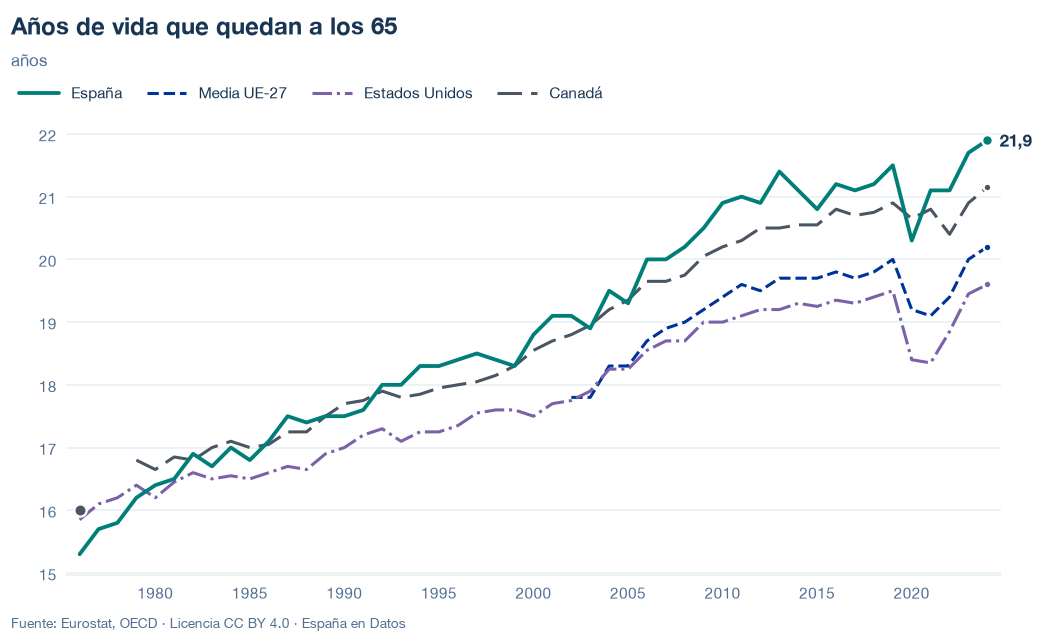

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/esperanza-vida-65.json y data/esperanza-vida-65.csv


## 6. Fuentes, notas y licencia

- Eurostat, `demo_mlexpec` (`Y65`, `T`, `M`, `F`, `YR`): España y UE-27.
- OCDE, `OECD.ELS.HD,DSD_HEALTH_STAT@DF_LE,1.1` (`LFEXP`, `Y65`, `M` y `F`): EE. UU., Canadá y, para comparar, España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.